# Notebook 02 · Calibración interna con 2022

**Pregunta:** ¿qué hiperparámetros selecciona el criterio de calibración de 2022?

**Entradas:** panel auditado, constantes MASE y predicciones internas registradas.
**Salida de modelado:** configuración congelada. **Salidas de revisión:** scores reconstruidos, ejemplos y figuras.

La ruta es **datos → variables de un mes → errores internos → score por configuración → selección**.
En modo `revisar`, esta notebook recalcula los scores desde las predicciones internas verificadas: no entrena
ni reemplaza la configuración entregada. Cada figura se dibuja aquí desde su tabla; no se carga un PNG previo.

La selección de hiperparámetros usa 2022. La formulación Δz se incorporó después de examinar la corrida principal
en niveles; por ello conserva su estatus exploratorio, aunque sus hiperparámetros se puntúen con 2022.

La auditoría de Notebook 01 está cerrada. En Colab, cambia `PROJECT_DIR` en la siguiente celda.
Para revisar la entrega, conserva `MODO = 'revisar'` y `CARPETA_RESULTADOS = 'resultados'`.
Para un entrenamiento nuevo, lee primero README.md: la ruta requiere otra carpeta y los niveles se reutilizan de v2.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    PROJECT_DIR = Path.cwd()  # En local, abrir desde la carpeta SIDPOL_Notebooks.
else:
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks')

MODO = 'revisar'  # 'revisar' no entrena. 'reentrenar' exige otra carpeta y el entorno fijado.
CARPETA_RESULTADOS = 'resultados'
sys.path.insert(0, str(PROJECT_DIR))
import sidpol as sp
import sidpol_figuras as sf

sp.require(MODO in ['revisar', 'reentrenar'], 'MODO debe ser revisar o reentrenar.')
P, ENV, panel, Q, districts = sp.setup(PROJECT_DIR, CARPETA_RESULTADOS)
if MODO == 'reentrenar':
    sp.require(CARPETA_RESULTADOS != 'resultados', 'Use otra carpeta para no sobrescribir la corrida entregada.')
    sp.require_training_environment(ENV)

print(f'Modo: {MODO} | Carpeta: {P.root / CARPETA_RESULTADOS}')
print('Entorno de esta ejecución:', ENV)
registros_figuras = []

Mounted at /content/drive


/content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks/sidpol.py:97: UserWarning: Versiones distintas de requirements_modelado.txt (esperada, actual): {'numpy': ('2.1.3', '2.4.6')}. En modo revisar se verifican archivos guardados y se registra este entorno. No se está reproduciendo el entrenamiento. Consulte README.md.
  warnings.warn(f'Versiones distintas de requirements_modelado.txt (esperada, actual): {wrong}. '


Modo: revisar | Carpeta: /content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks/resultados
Entorno de esta ejecución: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'xgboost': '3.4.1', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}


## 1. ¿Qué datos entran a la calibración?

Aunque el panel contiene observados posteriores, **ninguna fila de 2023–2026 entra en la puntuación ni en la
selección de hiperparámetros**. Los 12 meses que se pronostican internamente son enero–diciembre de 2022.
Esto no cambia la cronología exploratoria de Δz.

Para cada target y distrito, la constante $Q_d$ se carga desde la auditoría de 2018–2022 y no se recalcula.
En el código se llama `Q_j`. Se utiliza para puntuar los errores, no como variable de entrenamiento.
En particular, su periodo de referencia incluye 2022; las variables predictoras de cada mes usan únicamente su pasado.

In [2]:
panel_interno = panel[panel.fecha < '2023-01-01'].copy()
features = sp.build_features(panel_interno, districts)
display(sp.panel_summary(panel_interno))
sp.require(features.fecha.max() == pd.Timestamp('2022-12-01'), 'El corte interno debe terminar en 2022.')

,Distritos,Meses,Desde,Hasta,Denuncias/mes (mediana Lima)
target,,,,,
Robo,43,60,2018-01,2022-12,3076
Hurto,43,60,2018-01,2022-12,5008


## 2. Una fila real de modelado

Para pronosticar enero de 2022, el entrenamiento termina en diciembre de 2021.
Los rezagos y medias móviles se construyen **por target y distrito** y solo usan meses anteriores.
El distrito del ejemplo ocupa la posición central al ordenar el volumen mediano de 2018–2021;
no se elige por el desempeño del modelo.

Para un target fijo, $d$ identifica el distrito, $t$ el mes y $y_{d,t}$ las denuncias registradas:

$$
z_{d,t}=\log(1+y_{d,t}),
\qquad
\Delta z_{d,t}=z_{d,t}-z_{d,t-1}.
$$

`z = log1p(y)` es la respuesta en niveles y `dz = z - lag_1` la respuesta de la extensión exploratoria.
Una media móvil de $w$ meses utiliza los valores anteriores de la misma serie:

$$
\operatorname{lag}_{k,d,t}=z_{d,t-k},
\qquad
\overline{z}_{w,d,t}=\frac{1}{w}\sum_{i=1}^{w}z_{d,t-i},
\quad w\in\{3,6\}.
$$

Las variables relativas restan `lag_1` a los rezagos y medias móviles seleccionados. XGBoost-Δz también
conserva `lag_1` y UBIGEO. Las columnas `y`, `z` y `dz` que se muestran en el ejemplo sirven para identificar
la respuesta conocida en la evaluación retrospectiva; no son entradas predictoras del mismo mes.

Al volver a denuncias, los dos tipos de pronóstico utilizan:

$$
\widehat{y}^{\mathrm{niveles}}_{d,t}
=\max\!\left\{\exp(\widehat{z}_{d,t})-1,\,0\right\},
$$

$$
\widehat{y}^{\Delta z}_{d,t}
=\max\!\left\{\exp\!\left(z_{d,t-1}+\widehat{\Delta z}_{d,t}\right)-1,\,0\right\}.
$$

No se redondea a enteros ni se aplica corrección de sesgo (*smearing*).

In [3]:
casos_internos = sp.example_districts(panel, before='2022-01-01')
target_ejemplo = 'ROBO'
ubigeo_ejemplo = str(casos_internos.loc[casos_internos.target == target_ejemplo, 'UBIGEO'].iloc[0])
mes_interno = pd.Timestamp('2022-01-01')
serie = features[(features.target == target_ejemplo) & (features.UBIGEO.astype(str) == ubigeo_ejemplo)]
train_ejemplo = serie[serie.fecha < mes_interno]
fila_ejemplo = serie[serie.fecha == mes_interno]
print('Último mes de entrenamiento:', train_ejemplo.fecha.max().date())
print('Filas útiles de entrenamiento del distrito:', len(train_ejemplo))
display(fila_ejemplo[['fecha', 'UBIGEO', 'DIST_HECHO', 'y', 'z', 'lag_1', 'lag_12', 'rolling_mean_3', 'dz']])
sp.require(len(train_ejemplo) == 36, 'En el primer mes interno deben quedar 36 filas útiles por distrito.')

# Comprobar dos variables a mano con los meses anteriores, sin usar y del mes pronosticado.
historia = panel_interno[(panel_interno.target == target_ejemplo)
    & (panel_interno.UBIGEO.astype(str) == ubigeo_ejemplo)
    & (panel_interno.fecha < mes_interno)].sort_values('fecha')
lag1_manual = np.log1p(historia.y.iloc[-1])
rolling3_manual = np.log1p(historia.y.tail(3)).mean()
sp.require(np.isclose(lag1_manual, fila_ejemplo.lag_1.iloc[0]), 'No coincide lag_1.')
sp.require(np.isclose(rolling3_manual, fila_ejemplo.rolling_mean_3.iloc[0]), 'No coincide rolling_mean_3.')
print('lag_1 y rolling_mean_3 coinciden con el cálculo manual usando solo el pasado.')

Último mes de entrenamiento: 2021-12-01
Filas útiles de entrenamiento del distrito: 36


,fecha,UBIGEO,DIST_HECHO,y,z,lag_1,lag_12,rolling_mean_3,dz
2676,2022-01-01,150113,JESUS MARIA,40,3.713572,3.258097,2.890372,3.474788,0.455476


lag_1 y rolling_mean_3 coinciden con el cálculo manual usando solo el pasado.


## 3. Reconstruir los scores y seleccionar configuraciones

Para cada configuración: **promedio de los 12 errores escalados por distrito → mediana entre 43 distritos**.
No se toma la mediana de todas las filas distrito–mes.

Para una estrategia y un target fijos, $c$ representa una configuración y $\mathcal{T}_{2022}$ los 12 meses de 2022:

$$
\operatorname{Score}(c)=
\operatorname{mediana}_{d=1,\ldots,43}
\left[
\frac{1}{12}\sum_{t\in\mathcal{T}_{2022}}
\frac{\lvert y_{d,t}-\widehat{y}^{(c)}_{d,t}\rvert}{Q_d}
\right].
$$

Se elige el menor score por estrategia y target. En XGBoost, los empates se resuelven con menor profundidad y
luego menos árboles; en Ridge, con mayor penalización. No se calibra una configuración distinta para cada distrito.

En niveles se reutiliza la calibración original verificada. Para Δz/Ridge, `revisar` lee las predicciones internas;
`reentrenar` las calcula de nuevo en otra carpeta. La selección de hiperparámetros no utiliza los errores externos.

In [4]:
level_pred = sp.load_evidence(P, 'calibracion_niveles_original/notebook02_internal_predictions.csv')
level_pred['origin'] = pd.to_datetime(level_pred.origin)
level_pred, level_scores = sp.calibration_scores(
    level_pred, ['target', 'strategy', 'max_depth', 'n_estimators'], Q)
level_selected = (level_scores.sort_values(['target', 'strategy', 'Score', 'max_depth', 'n_estimators'])
                  .groupby(['target', 'strategy']).head(1))

if MODO == 'revisar':
    config, dz_pred_guardadas, scores_guardados = sp.read_saved_calibration(P)
    dz_pred, dz_scores, dz_selected = sp.score_dz_predictions(dz_pred_guardadas, Q)
else:
    sp.require(not P.config.exists(), 'Esa carpeta ya contiene una calibración. Use otra o cambie a revisar.')
    dz_pred, dz_scores, dz_selected = sp.calibrate_dz(features, districts, Q)
    sp.freeze_config(P, ENV, panel, level_scores, level_selected, dz_pred, dz_scores, dz_selected)
    config = sp.load_config(P)
    scores_guardados = pd.read_csv(P.scores, float_precision='round_trip')

scores_calculados = pd.concat([
    level_scores.assign(formulation='niveles', config_id=lambda d: 'd' + d.max_depth.astype(int).astype(str)
                        + '_n' + d.n_estimators.astype(int).astype(str)),
    dz_scores.assign(formulation='dz')], ignore_index=True)
claves_score = ['formulation', 'target', 'strategy', 'config_id']
comparacion_scores = scores_calculados.merge(scores_guardados, on=claves_score,
    suffixes=('_calculado', '_guardado'), validate='one_to_one')
sp.require(len(comparacion_scores) == len(scores_calculados) == len(scores_guardados) == 106,
           'Faltan configuraciones internas.')
sp.require(np.allclose(comparacion_scores.Score_calculado, comparacion_scores.Score_guardado,
                       rtol=0, atol=1e-12), 'Los scores reconstruidos no coinciden.')

for target in sp.TARGETS:
    for tabla, strategy, clave in [(level_selected, 'local', 'H_L'), (level_selected, 'global', 'H_G'),
                                   (dz_selected, 'local', 'H_L5'), (dz_selected, 'global', 'H_G5')]:
        elegido = tabla[(tabla.target == target) & (tabla.strategy == strategy)].iloc[0]
        h = config['selected'][target][clave]
        sp.require((int(elegido.max_depth), int(elegido.n_estimators)) == (h['max_depth'], h['n_estimators']),
                   f'La selección no coincide: {target}/{clave}.')
    ridge = dz_selected[(dz_selected.target == target) & (dz_selected.strategy == 'ridge')].iloc[0]
    sp.require(float(ridge.alpha) == config['selected'][target]['ridge_alpha'], 'Selección Ridge diferente.')
display(sp.selection_table(config['selected']))
print('106 scores y las configuraciones seleccionadas verificados.')

,Estatus,Robo,Hurto
profundidad × árboles · score 2022,,,
Local · niveles (H_L),Principal,2 × 100 · 0.606,2 × 100 · 0.629
Global · niveles (H_G),Sensibilidad,6 × 100 · 0.522,6 × 100 · 0.556
Local · Δz (H_L5),Exploratorio,1 × 25 · 0.513,1 × 25 · 0.524
Global · Δz (H_G5),Exploratorio,4 × 300 · 0.492,2 × 25 · 0.496
Ridge · Δz (α),Exploratorio,α = 100 · 0.542,α = 10 · 0.540
Naïve-1 (solo referencia),Referencia,— · 0.528,— · 0.530


106 scores y las configuraciones seleccionadas verificados.


## 4. Ejemplo completo: errores → MASE distrital → score

El siguiente bloque usa **las 12 predicciones registradas de 2022** de Local en niveles para el distrito del ejemplo.
Después calcula la media temporal de cada uno de los 43 distritos y comprueba el score de la configuración elegida.
`origin` identifica aquí el mes pronosticado, cuyo corte de entrenamiento es el mes anterior.

Antes de seguir: ¿por qué un score bajo en 2022 no garantiza una ventaja en los meses externos?

In [5]:
h = config['selected'][target_ejemplo]['H_L']
una_config = level_pred[(level_pred.target == target_ejemplo) & (level_pred.strategy == 'local')
    & level_pred.max_depth.eq(h['max_depth']) & level_pred.n_estimators.eq(h['n_estimators'])].copy()
ejemplo_12 = una_config[una_config.UBIGEO == ubigeo_ejemplo].sort_values('origin')
mase_43 = una_config.groupby('UBIGEO').scaled_error.mean()
score_manual = float(mase_43.median())
display(ejemplo_12[['origin', 'UBIGEO', 'y_true', 'y_pred', 'Q_j', 'scaled_error']])
print(f'MASE del distrito: {ejemplo_12.scaled_error.mean():.6f}')
print(f'Score: mediana de los 43 MASE = {score_manual:.6f}')
sp.require(len(ejemplo_12) == 12 and len(mase_43) == 43, 'El ejemplo debe cubrir 12 meses y 43 distritos.')
sp.require(np.isclose(score_manual, h['Score'], rtol=0, atol=1e-12), 'No coincide el score manual.')

,origin,UBIGEO,y_true,y_pred,Q_j,scaled_error
12,2022-01-01,150113,40.0,23.948532,22.9375,0.699792
55,2022-02-01,150113,30.0,29.472985,22.9375,0.022976
98,2022-03-01,150113,35.0,31.862164,22.9375,0.136799
141,2022-04-01,150113,29.0,26.924122,22.9375,0.090501
184,2022-05-01,150113,53.0,33.626584,22.9375,0.844618
227,2022-06-01,150113,28.0,38.589119,22.9375,0.461651
270,2022-07-01,150113,29.0,37.824460,22.9375,0.384718
313,2022-08-01,150113,35.0,32.778693,22.9375,0.096842
356,2022-09-01,150113,54.0,33.543508,22.9375,0.891836
399,2022-10-01,150113,37.0,37.668479,22.9375,0.029143


MASE del distrito: 0.606185
Score: mediana de los 43 MASE = 0.606185


## 5. Gráficos generados desde esos scores

Cada gráfico utiliza los scores reconstruidos en la sección 3, con las combinaciones **profundidad / árboles** explícitas.
La estrella señala la configuración seleccionada dentro de cada estrategia. Niveles y Δz usan grillas diferentes,
por lo que se grafican por separado. Ridge se conserva en la tabla de selección.

La línea de naïve-1 se reconstruye con el panel interno y sirve de referencia; no participa en la selección XGBoost.
Se generan cuatro gráficos: una combinación de target y formulación en cada uno.

,strategy,config_id,Score,seleccionada
0,global,d2_n100,0.561187,False
1,global,d2_n300,0.556176,False
2,global,d3_n100,0.569558,False
3,global,d3_n300,0.544674,False
4,global,d4_n100,0.528200,False
5,global,d4_n300,0.537276,False


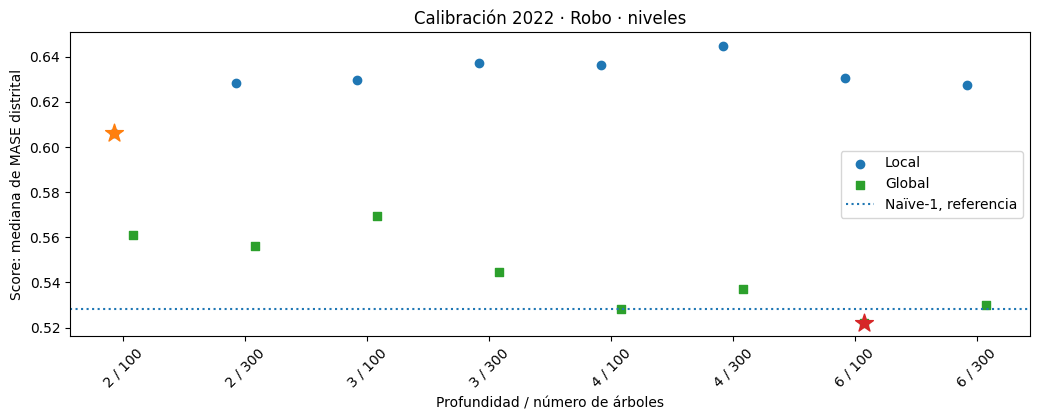

Datos: scores reconstruidos desde los 12 pronósticos internos por distrito. Estrella: configuración elegida.
Datos de esta figura: calibracion_robo_niveles_datos.csv


,strategy,config_id,Score,seleccionada
0,global,d1_n100,0.552757,False
1,global,d1_n25,0.535230,False
2,global,d1_n300,0.567845,False
3,global,d1_n50,0.540709,False
4,global,d2_n100,0.543472,False
5,global,d2_n25,0.534554,False


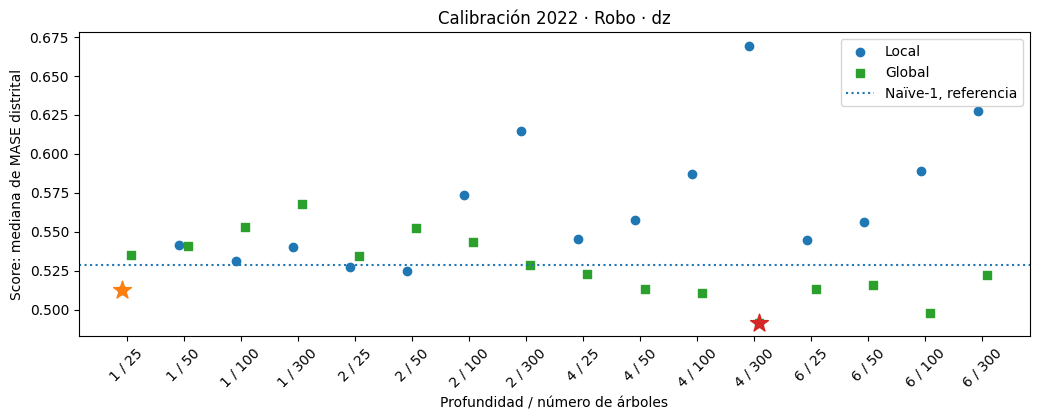

Datos: scores reconstruidos desde los 12 pronósticos internos por distrito. Estrella: configuración elegida.
Datos de esta figura: calibracion_robo_dz_datos.csv


,strategy,config_id,Score,seleccionada
0,global,d2_n100,0.562267,False
1,global,d2_n300,0.612403,False
2,global,d3_n100,0.576938,False
3,global,d3_n300,0.599014,False
4,global,d4_n100,0.578739,False
5,global,d4_n300,0.590739,False


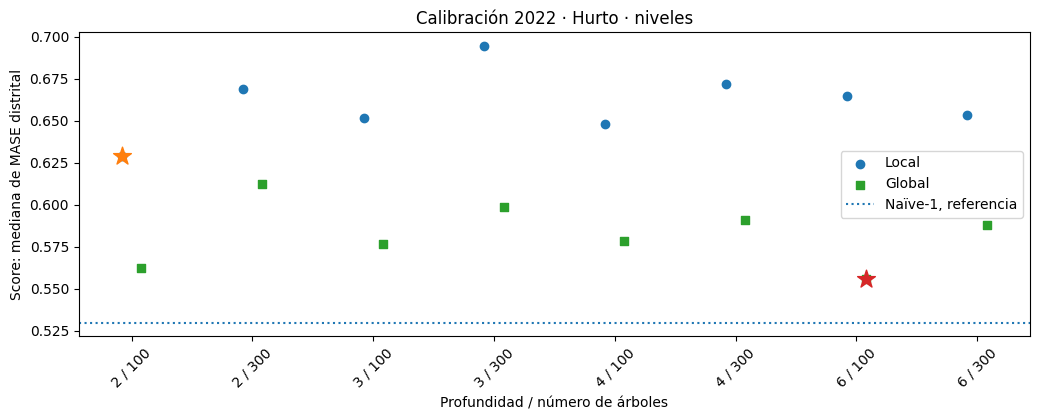

Datos: scores reconstruidos desde los 12 pronósticos internos por distrito. Estrella: configuración elegida.
Datos de esta figura: calibracion_hurto_niveles_datos.csv


,strategy,config_id,Score,seleccionada
0,global,d1_n100,0.538167,False
1,global,d1_n25,0.496772,False
2,global,d1_n300,0.572198,False
3,global,d1_n50,0.509046,False
4,global,d2_n100,0.560097,False
5,global,d2_n25,0.496392,True


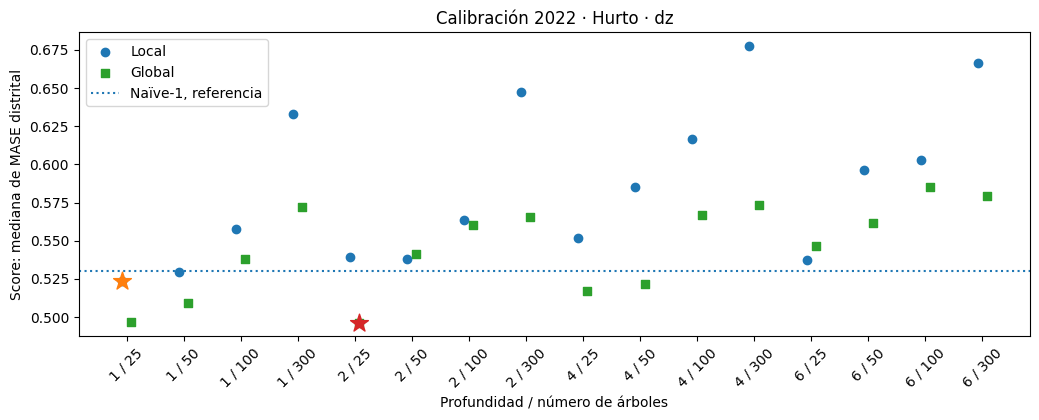

Datos: scores reconstruidos desde los 12 pronósticos internos por distrito. Estrella: configuración elegida.
Datos de esta figura: calibracion_hurto_dz_datos.csv


In [6]:
FIG = P.cal / 'figuras_notebook'
Y_interno = panel_interno.assign(UBIGEO=lambda d: d.UBIGEO.astype(str)).set_index(['target', 'UBIGEO', 'fecha']).y
for target in sp.TARGETS:
    ref = dz_pred[(dz_pred.target == target) & (dz_pred.strategy == 'ridge') & (dz_pred.config_id == 'a1')].copy()
    claves_previas = pd.MultiIndex.from_arrays([ref.target, ref.UBIGEO, ref.origin - pd.DateOffset(months=1)])
    ref['naive1'] = Y_interno.reindex(claves_previas).to_numpy()
    ref['error_naive1'] = (ref.y_true - ref.naive1).abs() / ref.Q_j
    score_naive = ref.groupby('UBIGEO').error_naive1.mean().median()
    sp.require(np.isclose(score_naive, config['selected'][target]['naive1_Score_2022'], atol=1e-12, rtol=0),
               'No coincide el naïve-1 interno.')
    for form in ['niveles', 'dz']:
        datos_grafico = scores_calculados[(scores_calculados.target == target)
            & (scores_calculados.formulation == form) & scores_calculados.strategy.isin(['local', 'global'])].copy()
        grid = datos_grafico[['max_depth', 'n_estimators']].drop_duplicates().sort_values(['max_depth', 'n_estimators'])
        grid['posicion'] = np.arange(len(grid))
        datos_grafico = datos_grafico.merge(grid, on=['max_depth', 'n_estimators'], validate='many_to_one')
        datos_grafico['seleccionada'] = False
        datos_grafico['score_naive1_2022'] = score_naive
        fig, ax = plt.subplots(figsize=(10.5, 4.3))
        for strategy, marker, offset in [('local', 'o', -0.08), ('global', 's', 0.08)]:
            serie_score = datos_grafico[datos_grafico.strategy == strategy].sort_values('posicion')
            ax.scatter(serie_score.posicion + offset, serie_score.Score, marker=marker, label=strategy.capitalize())
            best = serie_score.sort_values(['Score', 'max_depth', 'n_estimators']).iloc[0]
            datos_grafico.loc[(datos_grafico.strategy == strategy) & (datos_grafico.config_id == best.config_id), 'seleccionada'] = True
            ax.scatter(best.posicion + offset, best.Score, marker='*', s=180)
        ax.axhline(score_naive, linestyle=':', label='Naïve-1, referencia')
        ax.set_xticks(grid.posicion, [f'{int(d)} / {int(n)}' for d, n in zip(grid.max_depth, grid.n_estimators)], rotation=45)
        ax.set(xlabel='Profundidad / número de árboles', ylabel='Score: mediana de MASE distrital',
               title=f'Calibración 2022 · {sp.ES[target]} · {form}')
        ax.legend()
        display(datos_grafico[['strategy', 'config_id', 'Score', 'seleccionada']].head(6))
        registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG,
            f'calibracion_{target.lower()}_{form}',
            'Datos: scores reconstruidos desde los 12 pronósticos internos por distrito. Estrella: configuración elegida.',
            '02', '5. Scores internos'))

## 6. Cierre y transición a Notebook 03

Los hiperparámetros se determinan con el criterio de 2022 y se mantienen fijos al evaluar los meses externos.
En modo `revisar` no se reescriben la configuración ni los manifiestos de entrenamiento: se guardan las tablas de
comprobación y las figuras de esta lectura. El entorno de revisión se registra aparte; revisar no equivale a repetir
los ajustes originales ni convierte las extensiones exploratorias en confirmatorias.

**Para explicar:** muestra el recorrido de una predicción interna hasta el score de su configuración y la estrella
que aparece en el gráfico. Después abre Notebook 03 con el mismo `PROJECT_DIR` y la misma `CARPETA_RESULTADOS`.

In [7]:
sp.write_csv(FIG / 'ejemplo_12_errores.csv', ejemplo_12)
sp.write_csv(FIG / 'scores_reconstruidos.csv', scores_calculados)
display(sf.guardar_indice(registros_figuras, FIG))
sp.save_manifest(FIG, ENV, [f for f in FIG.iterdir() if f.is_file()],
    mode=MODO, training_performed=(MODO == 'reentrenar'),
    config_sha256=sp.sha256_file(P.config), scores_sha256=sp.sha256_file(P.scores),
    code_sha256={n: sp.sha256_file(PROJECT_DIR / n) for n in ['sidpol.py', 'sidpol_figuras.py']})
print('READY_FOR_NOTEBOOK_03 — configuración verificada y figuras generadas en esta ejecución.')

,notebook,seccion,figura,datos,filas
0,02,5. Scores internos,calibracion_robo_niveles.png,calibracion_robo_niveles_datos.csv,16
1,02,5. Scores internos,calibracion_robo_dz.png,calibracion_robo_dz_datos.csv,32
2,02,5. Scores internos,calibracion_hurto_niveles.png,calibracion_hurto_niveles_datos.csv,16
3,02,5. Scores internos,calibracion_hurto_dz.png,calibracion_hurto_dz_datos.csv,32


READY_FOR_NOTEBOOK_03 — configuración verificada y figuras generadas en esta ejecución.
